# NHANES 2013-2014 CHD Preprocessing (v2, person-level)

Selects the 19 model variables from the six NHANES CSV files, merges them **one row per participant** on `SEQN`, engineers the CHD label (`MCQ160C`), and runs the preprocessing pipeline (imputation, one-hot encoding, z-scoring, stratified split, SMOTE on the training set only).

**Changes from v1** (see `nhanes_chd_audit_and_revalidation.ipynb` for why):
1. `medications.csv` has one row per prescription. v1 outer-joined it directly, which repeated every participant once per medication (15,103 labeled rows for 5,751 people) and leaked the same person into both train and test. It is now collapsed to one row per `SEQN` (`n_prescriptions`) before the join, and the merge asserts uniqueness.
2. `MCQ160F` asks whether the **participant** ever had a stroke, not a relative. The column is now named `StrokeHistory` instead of `Blood-Rel Stroke`.
3. Paths are relative to the repository root, not a personal home directory.
4. The train/test split is now a split of participants, so the exported splits are safe for modeling. For the main results use participant-level cross-validation in the audit notebook.


In [1]:

from __future__ import annotations

from pathlib import Path
from difflib import SequenceMatcher
from typing import Dict, List, Optional, Tuple

import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from imblearn.over_sampling import SMOTE


In [2]:
# Paths are relative to the repository root: run from `notebooks/` or the repo root
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

raw_files = {
    "demographic.csv": RAW_DIR / "demographic.csv",
    "diet.csv": RAW_DIR / "diet.csv",
    "examination.csv": RAW_DIR / "examination.csv",
    "labs.csv": RAW_DIR / "labs.csv",
    "medications.csv": RAW_DIR / "medications.csv",
    "questionnaire.csv": RAW_DIR / "questionnaire.csv",
}

target_columns = [
    "Gender",
    "Age",
    "Systolic",
    "Diastolic",
    "Platelet Count",
    "Red-Cell Distribution Width",
    "Cholesterol",
    "Creatinine",
    "Glucose",
    "LDH",
    "Uric Acid",
    "Triglycerides",
    "HDL",
    "Glycohemoglobin",
    "Vigorous Work",
    "Moderate Work",
    "Diabetes",
    "Blood-Rel Diabetes",
    "StrokeHistory",  # MCQ160F: participant's own stroke history (was mislabeled "Blood-Rel Stroke" in v1)
]


In [3]:

# Resolve requested features to NHANES columns (manual + fuzzy fallback)
def read_column_names(path: Path) -> List[str]:
    try:
        return list(pd.read_csv(path, nrows=0).columns)
    except UnicodeDecodeError:
        return list(pd.read_csv(path, nrows=0, encoding="latin1").columns)

column_names = {name: read_column_names(path) for name, path in raw_files.items()}

manual_matches: Dict[str, Optional[Tuple[str, str]]] = {
    "Gender": ("demographic.csv", "RIAGENDR"),
    "Age": ("demographic.csv", "RIDAGEYR"),
    "Systolic": ("examination.csv", "BPXSY1"),
    "Diastolic": ("examination.csv", "BPXDI1"),
    "Platelet Count": ("labs.csv", "LBXPLTSI"),
    "Red-Cell Distribution Width": ("labs.csv", "LBXRDW"),
    "Cholesterol": ("labs.csv", "LBXSCH"),
    "Creatinine": ("labs.csv", "LBXSCR"),
    "Glucose": ("labs.csv", "LBXSGL"),
    "LDH": ("labs.csv", "LBXSLDSI"),
    "Uric Acid": ("labs.csv", "LBXSUA"),
    "Triglycerides": ("labs.csv", "LBXTR"),
    "HDL": ("labs.csv", "LBDHDD"),
    "Glycohemoglobin": ("labs.csv", "LBXGH"),
    "Vigorous Work": ("questionnaire.csv", "PAQ605"),
    "Moderate Work": ("questionnaire.csv", "PAQ620"),
    "Diabetes": ("questionnaire.csv", "DIQ010"),
    "Blood-Rel Diabetes": ("questionnaire.csv", "MCQ300C"),
    "StrokeHistory": ("questionnaire.csv", "MCQ160F"),
}


def best_match(target: str) -> Tuple[Optional[str], Optional[str], float]:
    best_file, best_col, best_score = None, None, 0.0
    for file_name, cols in column_names.items():
        for col in cols:
            score = SequenceMatcher(None, target.lower(), col.lower()).ratio()
            if score > best_score:
                best_file, best_col, best_score = file_name, col, score
    return best_file, best_col, best_score

resolved_matches: Dict[str, Dict[str, Optional[object]]] = {}
missing_targets: List[str] = []
threshold = 0.45

for target in target_columns:
    if target in manual_matches:
        file_name, column = manual_matches[target]
        available_cols = column_names.get(file_name, [])
        if column not in available_cols:
            resolved_matches[target] = {
                "file": None,
                "column": None,
                "match_score": None,
                "notes": f"{target}: manual code {column} not present in {file_name}",
            }
            missing_targets.append(target)
            continue
        resolved_matches[target] = {
            "file": file_name,
            "column": column,
            "match_score": 1.0,
            "notes": "manual mapping",
        }
        continue

    file_name, column, score = best_match(target)
    if score >= threshold:
        resolved_matches[target] = {
            "file": file_name,
            "column": column,
            "match_score": round(score, 3),
            "notes": "auto-selected",
        }
    else:
        resolved_matches[target] = {
            "file": None,
            "column": None,
            "match_score": round(score, 3),
            "notes": "no close match",
        }
        missing_targets.append(target)

available_targets = [t for t in target_columns if t not in missing_targets]

match_df = pd.DataFrame.from_dict(resolved_matches, orient="index")
match_df


,file,column,match_score,notes
Gender,demographic.csv,RIAGENDR,1.0,manual mapping
Age,demographic.csv,RIDAGEYR,1.0,manual mapping
Systolic,examination.csv,BPXSY1,1.0,manual mapping
Diastolic,examination.csv,BPXDI1,1.0,manual mapping
Platelet Count,labs.csv,LBXPLTSI,1.0,manual mapping
Red-Cell Distribution Width,labs.csv,LBXRDW,1.0,manual mapping
Cholesterol,labs.csv,LBXSCH,1.0,manual mapping
Creatinine,labs.csv,LBXSCR,1.0,manual mapping
Glucose,labs.csv,LBXSGL,1.0,manual mapping
LDH,labs.csv,LBXSLDSI,1.0,manual mapping


In [4]:
# Pull columns, merge ONE ROW PER PARTICIPANT on SEQN, engineer labels
columns_by_file: dict[str, set[str]] = {name: {"SEQN"} for name in raw_files}

for target, info in resolved_matches.items():
    file_name = info["file"]
    column = info["column"]
    if file_name and column:
        columns_by_file[file_name].add(column)

columns_by_file["questionnaire.csv"].add("MCQ160C")  # CHD indicator used for the label


def read_selected(file_name: str, cols: set[str]) -> pd.DataFrame:
    try:
        return pd.read_csv(raw_files[file_name], usecols=sorted(cols), low_memory=False)
    except UnicodeDecodeError:
        return pd.read_csv(raw_files[file_name], usecols=sorted(cols), low_memory=False, encoding="latin1")


selected_frames: dict[str, pd.DataFrame] = {}
for file_name, cols in columns_by_file.items():
    df = read_selected(file_name, cols)
    if file_name == "medications.csv":
        # One row per prescription -> collapse to one row per participant.
        # None of the 19 model variables comes from this file; keep only a count.
        df = df.groupby("SEQN").size().rename("n_prescriptions").reset_index()
    else:
        # Every other file should already be one row per participant; make it explicit.
        df = df.drop_duplicates(subset="SEQN")
    selected_frames[file_name] = df

# Start from demographics (the participant roster) and LEFT-join the rest, so the
# row count can only equal the number of participants.
merged_df = selected_frames["demographic.csv"].copy()
for file_name, df in selected_frames.items():
    if file_name == "demographic.csv":
        continue
    merged_df = merged_df.merge(df, on="SEQN", how="left")

assert merged_df["SEQN"].is_unique, "Merge produced more than one row per participant"
print(f"Participants after merge: {len(merged_df):,} (one row each)")

rename_map = {info["column"]: target for target, info in resolved_matches.items() if info["column"] is not None}
renamed_df = merged_df.rename(columns=rename_map)

renamed_df["Gender"] = renamed_df["Gender"].map({1: "Male", 2: "Female"})
renamed_df["StrokeHistory"] = renamed_df["StrokeHistory"].map({1: "Yes", 2: "No"})
renamed_df["disease_status"] = renamed_df["MCQ160C"].map({1: "diseased", 2: "normal"})
renamed_df = renamed_df.drop(columns=["MCQ160C"])

for col in available_targets:
    if col not in renamed_df.columns:
        renamed_df[col] = np.nan

selected_df = renamed_df[["SEQN"] + available_targets + ["n_prescriptions", "disease_status"]].copy()
selected_df["n_prescriptions"] = selected_df["n_prescriptions"].fillna(0).astype(int)

selected_path = PROCESSED_DIR / "selected_features.csv"
selected_df.to_csv(selected_path, index=False)

dropped_cols = [t for t in target_columns if t not in available_targets]
print("Saved selected features to", selected_path)
print("Dropped targets (missing in raw files):", dropped_cols or "none")
print("Rows with a valid CHD label:", selected_df["disease_status"].notna().sum())
selected_df.head()


Participants after merge: 10,175 (one row each)
Saved selected features to D:\Desktop\Project\2026new\nhanes-chd-improved-02\nhanes-chd\data\processed\selected_features.csv
Dropped targets (missing in raw files): none
Rows with a valid CHD label: 5751


,SEQN,Gender,Age,Systolic,Diastolic,Platelet Count,Red-Cell Distribution Width,Cholesterol,Creatinine,Glucose,...,Triglycerides,HDL,Glycohemoglobin,Vigorous Work,Moderate Work,Diabetes,Blood-Rel Diabetes,StrokeHistory,n_prescriptions,disease_status
0,73557,Male,69,122.0,72.0,204.0,14.0,168.0,1.21,554.0,...,NaN,65.0,13.9,2.0,2.0,1.0,1.0,Yes,2,normal
1,73558,Male,54,156.0,62.0,314.0,13.4,167.0,0.79,219.0,...,NaN,50.0,9.1,2.0,1.0,1.0,1.0,No,4,normal
2,73559,Male,72,140.0,90.0,237.0,13.4,127.0,1.22,183.0,...,51.0,60.0,8.9,2.0,1.0,1.0,2.0,No,5,normal
3,73560,Male,9,108.0,38.0,240.0,13.7,NaN,NaN,NaN,...,NaN,61.0,NaN,NaN,NaN,2.0,NaN,NaN,1,NaN
4,73561,Female,73,136.0,86.0,300.0,12.3,207.0,0.73,104.0,...,75.0,85.0,4.9,2.0,1.0,2.0,2.0,No,4,normal


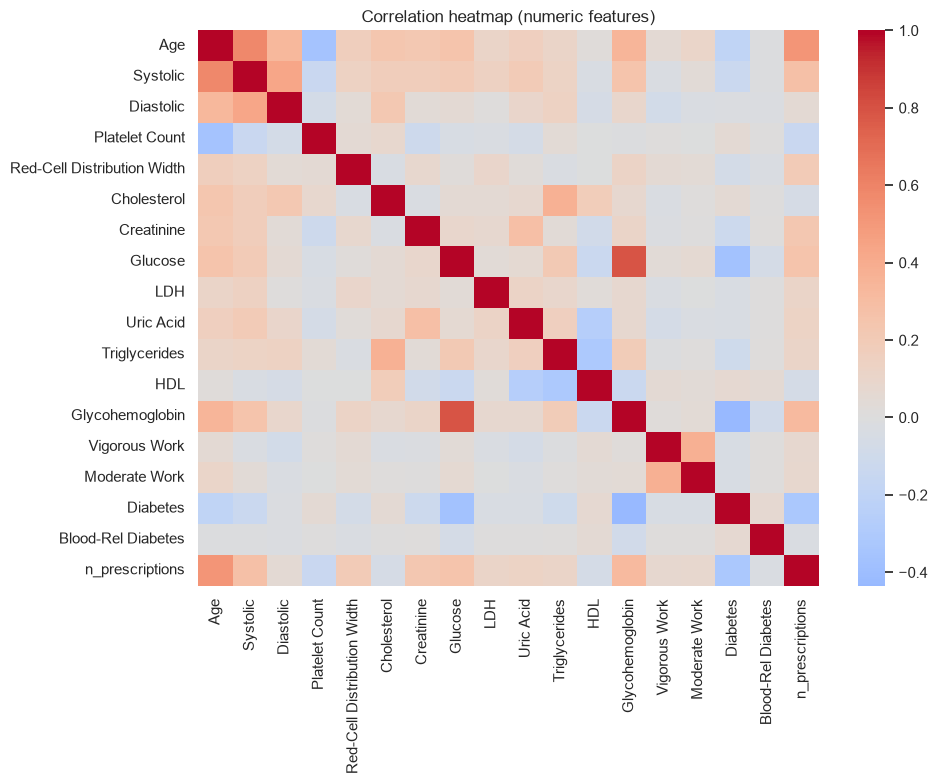

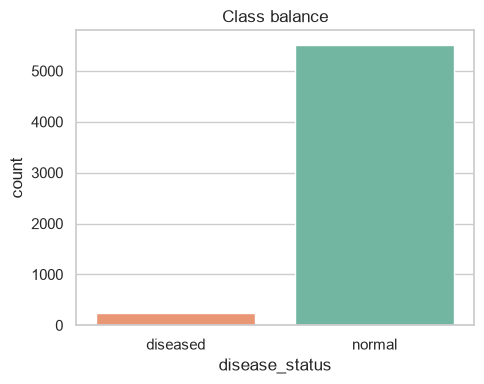

In [5]:
# Quick EDA: correlations (numeric only) + class balance
sns.set_theme(style="whitegrid", context="notebook")

numeric_cols = selected_df.drop(columns=["SEQN"]).select_dtypes(include=[np.number]).columns
correlation_matrix = selected_df[numeric_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, cmap="coolwarm", center=0)
plt.title("Correlation heatmap (numeric features)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(5, 4))
sns.countplot(data=selected_df, x="disease_status", order=["diseased", "normal"], hue="disease_status", palette="Set2", legend=False)
plt.title("Class balance")
plt.tight_layout()
plt.show()


## Workflow overview

- Select and harmonize the requested NHANES features across files keyed by `SEQN`, collapsing the per-prescription medications file first.
- Engineer the label (`MCQ160C`), keep family-history-of-diabetes and own-stroke flags; drop unmapped targets.
- Quick EDA for correlations and class balance.
- Preprocess with imputers, one-hot encoding and z-score scaling; save the full preprocessed dataset (one row per participant).
- Create a stratified **participant-level** train/test split, then balance only the training set with SMOTE; save all splits.

Note: `heart_disease_preprocessed.csv` fits the imputer and scaler on the full dataset. That is fine for exploration, but the headline model results come from the audit notebook, where imputation and scaling are fit inside each cross-validation fold.


In [6]:

# Preprocess: impute missing values, one-hot encode categoricals, scale numerics, balance train set
feature_columns = available_targets  # n_prescriptions is NOT a model feature (not in the paper)
target_column = "disease_status"

categorical_features = [
    "Gender",
    "Vigorous Work",
    "Moderate Work",
    "Diabetes",
    "Blood-Rel Diabetes",
    "StrokeHistory",
]

categorical_features = [c for c in categorical_features if c in feature_columns]
numeric_features = sorted(set(feature_columns) - set(categorical_features))

numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="mean")),
        ("scaler", StandardScaler()),
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore")),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features),
    ],
)

valid_mask = selected_df[target_column].notna()
print(f"Rows with valid disease_status label: {valid_mask.sum()} / {len(selected_df)}")
df_valid = selected_df.loc[valid_mask].reset_index(drop=True)

X = df_valid[feature_columns]
y = df_valid[target_column]

X_processed = preprocessor.fit_transform(X)
if hasattr(X_processed, "toarray"):
    X_processed = X_processed.toarray()
processed_feature_names = preprocessor.get_feature_names_out()
readable_feature_names = [name.split("__", 1)[-1] if "__" in name else name for name in processed_feature_names]

X_processed_df = pd.DataFrame(X_processed, columns=readable_feature_names)

X_processed_df.insert(0, "SEQN", df_valid["SEQN"].values)
X_processed_df[target_column] = y.values

processed_path = PROCESSED_DIR / "heart_disease_preprocessed.csv"
X_processed_df.to_csv(processed_path, index=False)
print("Saved preprocessed data to", processed_path)

X_model = X_processed_df.drop(columns=[target_column, "SEQN"])
y_model = X_processed_df[target_column]

print("Class distribution:", y_model.value_counts())

X_train, X_test, y_train, y_test = train_test_split(
    X_model,
    y_model,
    test_size=0.30,
    stratify=y_model,
    random_state=42,
)

train_df = X_train.copy()
train_df.insert(0, "SEQN", X_processed_df.loc[X_train.index, "SEQN"].values)
train_df[target_column] = y_train.values

test_df = X_test.copy()
test_df.insert(0, "SEQN", X_processed_df.loc[X_test.index, "SEQN"].values)
test_df[target_column] = y_test.values

train_path = PROCESSED_DIR / "train_split.csv"
test_path = PROCESSED_DIR / "test_split.csv"

train_df.to_csv(train_path, index=False)
test_df.to_csv(test_path, index=False)

print("Train set saved to", train_path, "| shape:", train_df.shape)
print("Test set saved to", test_path, "| shape:", test_df.shape)

smote = SMOTE(random_state=42, k_neighbors=5)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train, y_train)

smote_train_df = pd.DataFrame(X_train_balanced, columns=X_train.columns)
smote_train_df[target_column] = y_train_balanced.values

smote_train_path = PROCESSED_DIR / "train_split_smote.csv"
smote_train_df.to_csv(smote_train_path, index=False)

print("Post-SMOTE train class distribution:", y_train_balanced.value_counts())
print("SMOTE-balanced train set saved to", smote_train_path, "| shape:", smote_train_df.shape)

# Safety check: no participant may appear on both sides of the split
assert not set(train_df["SEQN"]) & set(test_df["SEQN"]), "Participant leakage between train and test"
print("No participant overlap between train and test.")


Rows with valid disease_status label: 5751 / 10175
Saved preprocessed data to D:\Desktop\Project\2026new\nhanes-chd-improved-02\nhanes-chd\data\processed\heart_disease_preprocessed.csv
Class distribution: disease_status
normal      5519
diseased     232
Name: count, dtype: int64
Train set saved to D:\Desktop\Project\2026new\nhanes-chd-improved-02\nhanes-chd\data\processed\train_split.csv | shape: (4025, 33)
Test set saved to D:\Desktop\Project\2026new\nhanes-chd-improved-02\nhanes-chd\data\processed\test_split.csv | shape: (1726, 33)


Post-SMOTE train class distribution: disease_status
diseased    3863
normal      3863
Name: count, dtype: int64
SMOTE-balanced train set saved to D:\Desktop\Project\2026new\nhanes-chd-improved-02\nhanes-chd\data\processed\train_split_smote.csv | shape: (7726, 32)
No participant overlap between train and test.
